In [3]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Import library

In [2]:

from sklearn.decomposition import PCA
from kmeans_pytorch import kmeans
from matplotlib.lines import Line2D
from sentence_transformers import SentenceTransformer, util , SimilarityFunction


import pandas as pd
import numpy as np
import regex as re
import networkx as nx
import itertools as it
import matplotlib.pyplot as plt
import pickle
import os
import torch
import seaborn as sns 
import nltk
import sys



/Users/gl665/PycharmProjects/Phrame_MentalMaps/.venv/lib/python3.12/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:11: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm, trange
2024-05-29 14:14:52.865975: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [8]:
# Add the src directory to the sys.path
sys.path.append(os.path.abspath(os.path.join('..', 'src')))
print(sys.path)
import data_io

['/Library/Frameworks/Python.framework/Versions/3.12/lib/python312.zip', '/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12', '/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/lib-dynload', '', '/Users/gl665/PycharmProjects/Phrame_MentalMaps/.venv/lib/python3.12/site-packages', '/Users/gl665/PycharmProjects/Phrame_MentalMaps/src']


# Read data


## SYNCH Project 

In [12]:
new_dir = "/Users/gl665/PycharmProjects/Phrame_MentalMaps"
# Change the current working directory
os.chdir(new_dir)


my_data_RC = {}
folder_path = 'results/SYNCH/JSON_file/RC/'

my_data_RC = data_io.read_json(folder_path, my_data_RC)
my_data_RC


load: FM 51220Clean.json
load: Passages Clean.json
load: full circle GBM 5 24 21clean.json
load: C 7 6 20 clean model.json
load: Wavi combined clean.json
load: drug justice model clean.json
load: DSS23.json
load: E clean model 572020.json
load: nat model clean2.json
load: FC Prov Clean.json
load: full circle clean.json
load: reentry clean model.json
load: DV justice model clean.json


{'FM 51220Clean.json': [{1: 'abandonment',
   2: 'ability to navigate colonial spaces',
   3: 'acceptance of alcohol as coping behavior',
   4: 'acceptance of sexual assault',
   5: 'acceptance of violence',
   6: 'accessing healing resources',
   7: 'accessing victim resources',
   8: 'advocacy for equity and justice',
   9: 'alcohol misuse',
   10: 'attaining resources for success',
   11: 'attaining scholastic success',
   12: 'attaining success in colonial spaces',
   13: 'availability of healing resources',
   14: 'availability of victim support and resources',
   15: 'biracial/blood quantum racism',
   16: 'boarding school',
   17: 'bringing success to tribe',
   18: 'child abuse/aces',
   19: 'child in foster system',
   20: 'child removed from home',
   21: 'child witness ipv',
   22: 'coerced reproduction',
   23: 'colonial environment pushback',
   24: 'colonial environment/lakota identity clashes',
   25: 'colonial violence',
   26: 'community-level trauma',
   27: 'cultural

In [ ]:
# with open('Output/SYNCH/SYNCH_file_rename.pkl', 'rb') as file:
#     synch_rename_files = pickle.load(file)

In [ ]:
# my_data = my_data_RC | my_data_PR

# file_groups = {key: 'RC' if 'RC' in key else 'PR' for key in synch_rename_files.values()}


for renaming overcome datat: overcome_file_rename.pkl


## OVERCOME Project 


In [89]:
# # Write pickle file
# with open('overcome_file_rename.pkl', 'wb') as file:
#     pickle.dump(overcome_file_rename, file)

# with open('Output/Overcome/overcome_file_rename.pkl', 'rb') as file:
#     rc_rename_files = pickle.load(file)
#     
# print(rc_rename_files)
# 
# # create a dictionary pairing file names with their respective groups
# file_groups = {key: 'RC' if 'RC' in key else 'SF' for key in my_data.keys()}
# file_groups

# my_data = {rc_rename_files.get(key, key): value for key, value in my_data.items()}
# my_data.keys()

{'Overcome RC4 6-7-2023.json': 'RC4', 'Overcome RC1 4-5-2023.json': 'RC1', 'overcome RC2 4-5-2023.json': 'RC2', 'Overcome 5 6-7-2023.json': 'RC5', 'overcome RC3 5-5-2023.json': 'RC3', 'Overcome SF3 - 5- 10 - 2023.json': 'SF3', 'SF2-4-28-2023.json': 'SF2', 'SF1-4-26-2023 revised.json': 'SF1', 'SF5-5-18-2023.json': 'SF5', 'Ocome SF3 -5 10 23 revised.json': 'SF3', 'SF1-4-26-2023.json': 'SF1', 'Overcome SF4 - 5 - 10 - 2023.json': 'SF4'}


{'Overcome RC4 6-7-2023.json': 'RC',
 'SF2-4-28-2023.json': 'SF',
 'SF5-5-18-2023.json': 'SF',
 'Overcome RC1 4-5-2023.json': 'RC',
 'overcome RC2 4-5-2023.json': 'RC',
 'Ocome SF3 -5 10 23 revised.json': 'SF',
 'Overcome 5 6-7-2023.json': 'SF',
 'SF1-4-26-2023.json': 'SF',
 'Overcome SF4 - 5 - 10 - 2023.json': 'SF',
 'overcome RC3 5-5-2023.json': 'RC'}

# Term Frequency Inverse Document Frequency (TFIDF). 
Step 1. The TF-IDF is applied to the preprocessed data to transform it into an integer form so that clustering algorithms can use it. 

TFIdf way to measure how unique a certain word is relative to every other word in a document. This is calculated on a scale from 0–1 with the most common words approaching 0 and the most unique words approaching 1. 

In [89]:
string_list = []

for i in my_data: 
    string_list.append(', '.join(list(my_data[i][0].values())))
    
# print(string_list[:1])
print("Number of paragraphs (CLd)s :", len(string_list))

Number of paragraphs (CLd)s : 34


In [90]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(string_list)
arr = X.toarray()

In [52]:
# from sklearn.metrics.pairwise import cosine_similarity
# 
# def create_heatmap(similarity, cmap = "YlGnBu"):
#   df = pd.DataFrame(similarity)
#   mask = np.tril(np.ones(df.shape, dtype=bool))
# 
#   df.columns = df_cld['dataset']
#   df.index = df_cld['dataset']
#   fig, ax = plt.subplots(figsize=(5,5))
#   sns.heatmap(df, cmap=cmap, annot=True, ax=ax, mask = mask)

# Perform K-Means Clustering on the Embedded Data

### functions 

In [91]:
def detect_clusters(X, nclusters, tol=1e-6):
    # Convert input data to PyTorch tensor
    X = torch.as_tensor(X, dtype=torch.float32)
    assert X.ndim == 2

    # Apply PCA to reduce dimensionality
    pca = PCA(n_components=2)
    X1 = torch.from_numpy(pca.fit_transform(X.numpy()))

    # Run kmeans on the PCA-transformed data with Euclidean distance
    cluster_ID, C = kmeans(X1, nclusters, distance='euclidean', tol=tol)
    return cluster_ID, C


In [92]:
# Define a dictionary mapping labels to markers

def cluster_plot(X, group_labels, cluster_labels, group_dict = None, annotations = None, ax = None):
    """
      Visualizes clusters of text data.
    :param X: array-like, shape (n_samples, n_features)
        The text data points.
    :param group_dict: 
    :param group_labels: list of str
        Labels for each group in the data.
    :param cluster_labels: array-like, shape (n_samples,)
        Cluster labels for each point in X.
    :param annotations: ist of str, optional
        Annotations for each data point.
    :param ax: matplotlib.axes.Axes, optional
        The axes on which to draw the plot. If None, a new figure and axes will be created.
    :return: plot 
    """
   
    if ax is None: 
        fig, ax = plt.subplots()  # Explicit figure and axes with size
    
    # Plot points based on their group label with different markers and colors based on cluster labels
    if group_dict is None: 
        for cluster in np.unique(cluster_labels):
            group_points = X[(cluster_labels == cluster)]
            plt.scatter(group_points[:, 0], group_points[:, 1], color=f'C{cluster}', label=f'Cluster {cluster + 1}')
    else: 
        for group, marker in group_dict.items():
            for cluster in np.unique(cluster_labels):
                group_points = X[(group_labels == group) & (cluster_labels == cluster)]
                plt.scatter(group_points[:, 0], group_points[:, 1], marker=marker, color=f'C{cluster}', label=f'Cluster {cluster + 1}')

   # Annotate each point with the corresponding name from the annotations dictionary
    if annotations is not None:    
        for x, y in zip(X[:, 0], X[:, 1]):
            x_float = float(x)
            if x_float in annotations:
                ax.annotate(annotations[x_float], (x, y), fontsize=12, ha='left')

    xlim = plt.xlim()
    ylim = plt.ylim()
    
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    # Custom legend for markers
    if group_dict is not None: 
        marker_handles = [Line2D([0], [0], marker=marker, color='w', markerfacecolor='k', markersize=10, label=group)
                          for group, marker in group_dict.items()]
        legend1 = ax.legend(handles=marker_handles, loc='lower left', title='Groups')
        ax.add_artist(legend1)
        
    # Custom legend for colors
    color_handles = [Line2D([0], [0], marker='o', color='w', markerfacecolor=f'C{i}', markersize=10, label=f'Cluster {i + 1}')
                     for i in np.unique(cluster_labels)]
    legend2 = ax.legend(handles=color_handles, loc='lower right', title='Clusters')
    ax.add_artist(legend2)
    
    
    return ax

#TODO: this code below is for the unit tests. 
# # Example usage
# # Assuming X is your data array, group_labels contains 'RC' or 'SF' for each point, centers contains the cluster centers, and cluster_labels contains cluster assignments for each point
# X = np.random.randn(100, 2)
# group_labels = np.random.choice(['RC', 'SF'], 100)  # Random 'RC' or 'SF' labels
# centers = np.random.randn(4, 2)  # Example cluster centers
# cluster_labels = np.random.randint(0, 4, 100)  # Random cluster assignments for each point
# 
# cluster_visualization_new(X, group_labels, centers, cluster_labels)


## Run pretrained model 

In [15]:
# model = SentenceTransformer('paraphrase-MiniLM-L6-v2')
model = SentenceTransformer('all-mpnet-base-v2')
def get_embeddings(txt_list):
    return model.encode(txt_list, show_progress_bar=False, convert_to_numpy=True)
sentence_embeddings = get_embeddings(string_list)
print("Embedding shape:", sentence_embeddings.shape)

NameError: name 'string_list' is not defined

In [94]:
X =  torch.as_tensor(sentence_embeddings)

label, center = detect_clusters(X, 3)

running k-means on cpu..


[running kmeans]: 5it [00:00, 391.60it/s, center_shift=0.000000, iteration=5, tol=0.000001]


In [95]:
len(my_data)
len(file_groups)

34

In [96]:
# Create a dataframe to store the cluster labels
df_cluster = pd.DataFrame({'cluster': label, 'cluster_label': list(my_data.keys()), 'group': list(file_groups.values())})
# print the cluster dataframe
print(df_cluster.head(5))

   cluster                      cluster_label group
0        0                 FM 51220Clean.json    PR
1        1                Passages Clean.json    PR
2        1  full circle GBM 5 24 21clean.json    PR
3        1          C 7 6 20 clean model.json    PR
4        1             tracy clean model.json    PR


In [97]:
group_labels = np.array(df_cluster['group'])
cluster_labels = np.array(df_cluster['cluster'])
annotations = {float(x): name for x, name in zip(X[:, 0], df_cluster['cluster_label'])}


In [98]:
markers = [ 'o', '^', 
    '.', ',', 'v', '<', '>', '1', '2', '3', '4',
    '8', 's', 'p', '*', 'h', 'H', '+', 'x', 'X', 'D', 'd',
    '|', '_', 'P', 'X']

# Zip the group labels and markers into a dictionary
group_dict = dict(zip(np.unique(group_labels), markers[:len(np.unique(group_labels))]))
group_dict


{'PR': 'o', 'RC': '^'}

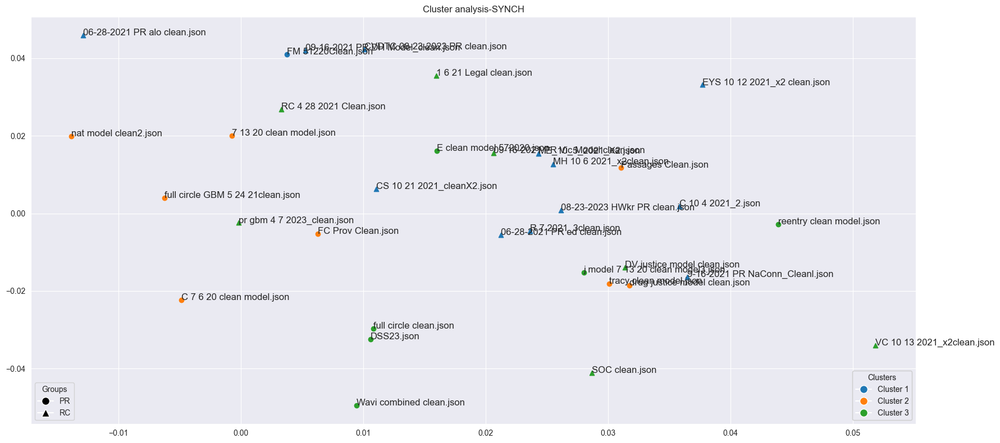

In [103]:
fig, ax = plt.subplots(figsize=(18, 8))
ax = cluster_plot(X, group_labels, cluster_labels, group_dict = group_dict, annotations = annotations,ax = ax)
ax.set_title("Cluster analysis-SYNCH")
plt.tight_layout()
plt.savefig('Output/SYNCH/Cluster/Cluster analysis -SYNCH.png')

plt.show()

## Single variable name clustering 

In [104]:
df_cld = pd.DataFrame()
# create column of dataset, each cell is the keys from my_data dictionary
df_cld['dataset'] = pd.Series(list(my_data.keys()))
df_cld['vars'] = df_cld['dataset'].apply(lambda x: list(my_data[x][0].values()))

df_cld.head(3)

,dataset,vars
0,FM 51220Clean.json,"[Mental Health, Intimate Partner Violence, Alc..."
1,Passages Clean.json,"[Alcohol Misuse, Intimate Partner Violence, ""N..."
2,full circle GBM 5 24 21clean.json,"[Drug use, IPV, Single Parent Homes, Sexual Ab..."


In [105]:
# Get embeddings of each variable in each text 

# Extract variable names and store them in a dictionary with paragraph indices
global_variable_dict = {}
def get_single_var_dictionary(text, index):
    variable_dict = {}
    for variables in text:
        var_names = [var.strip() for var in variables.split(',')]
        for var in var_names:
            variable_dict[var] = index
    return variable_dict

for i, text in zip(df_cld['dataset'],df_cld['vars']):
    variable_dict = get_single_var_dictionary(text, i)
    global_variable_dict.update(variable_dict)

In [106]:
# Print the first 5 rows of the global_variable_dict
print(list(global_variable_dict.items())[:5])


[('Mental Health', '9-16-2021 PR NaConn_Cleanl.json'), ('Intimate Partner Violence', '08-23-2023 HWkr PR clean.json'), ('Alcohol Misuse', 'C 10 4 2021_2.json'), ('Abandonment', 'FM 51220Clean.json'), ('Family Relationship Health', 'FM 51220Clean.json')]


In [108]:
var_list = list(global_variable_dict.keys())
var_embeddings = get_embeddings(var_list)
X =  torch.as_tensor(var_embeddings)

label, center = detect_clusters(X, 3)
# Create a dataframe to store the cluster labels
df_var_cluster = pd.DataFrame({'cluster': label, 'cluster_label': list(global_variable_dict.values()), 'cld variable': list(global_variable_dict.keys())})# print the cluster dataframe

df_var_cluster['file_index'] = df_var_cluster['cluster_label'].map(synch_rename_files) #TODO: delete this in overcome project 
df_var_cluster['group'] = df_var_cluster['file_index'].map(file_groups)

print(df_var_cluster.head(5))

running k-means on cpu..


[running kmeans]: 20it [00:00, 365.40it/s, center_shift=0.000000, iteration=20, tol=0.000001]

   cluster                    cluster_label                cld variable  \
0        2  9-16-2021 PR NaConn_Cleanl.json               Mental Health   
1        1    08-23-2023 HWkr PR clean.json   Intimate Partner Violence   
2        1               C 10 4 2021_2.json              Alcohol Misuse   
3        1               FM 51220Clean.json                 Abandonment   
4        0               FM 51220Clean.json  Family Relationship Health   

  file_index group  
0       PR13    PR  
1       PR15    PR  
2       PR11    PR  
3        RC1    RC  
4        RC1    RC  


In [109]:
group_labels = np.array(df_var_cluster['group'])
cluster_labels = np.array(df_var_cluster['cluster'])

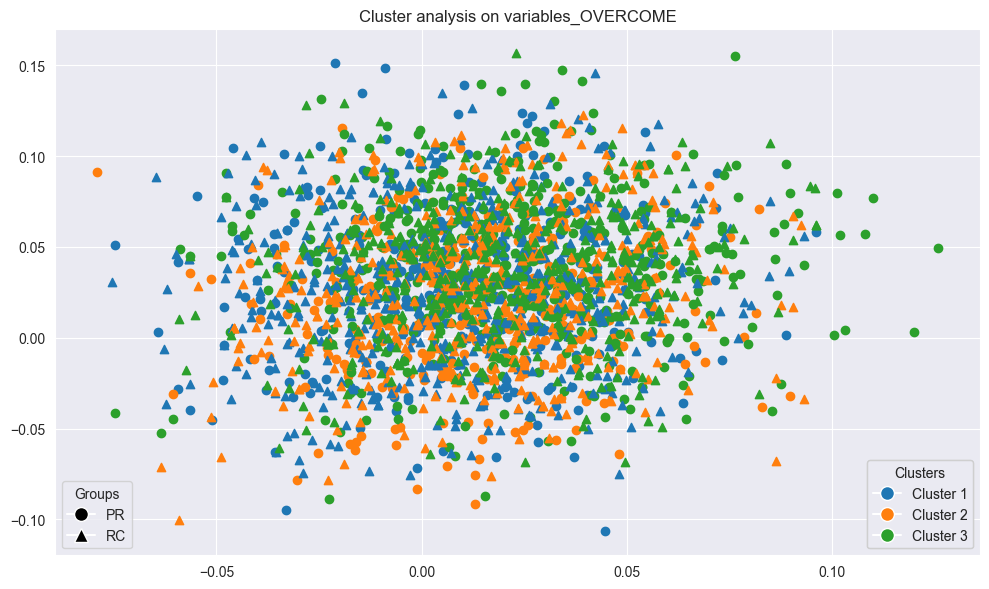

In [110]:

fig, ax = plt.subplots(figsize=(10, 6))
ax = cluster_plot(X, group_labels, cluster_labels, group_dict = group_dict, ax= ax)
plt.title("Cluster analysis on variables_OVERCOME")
plt.tight_layout()
plt.savefig('Output/SYNCH/Cluster/Cluster analysis var -SYNCH.png')
plt.show()



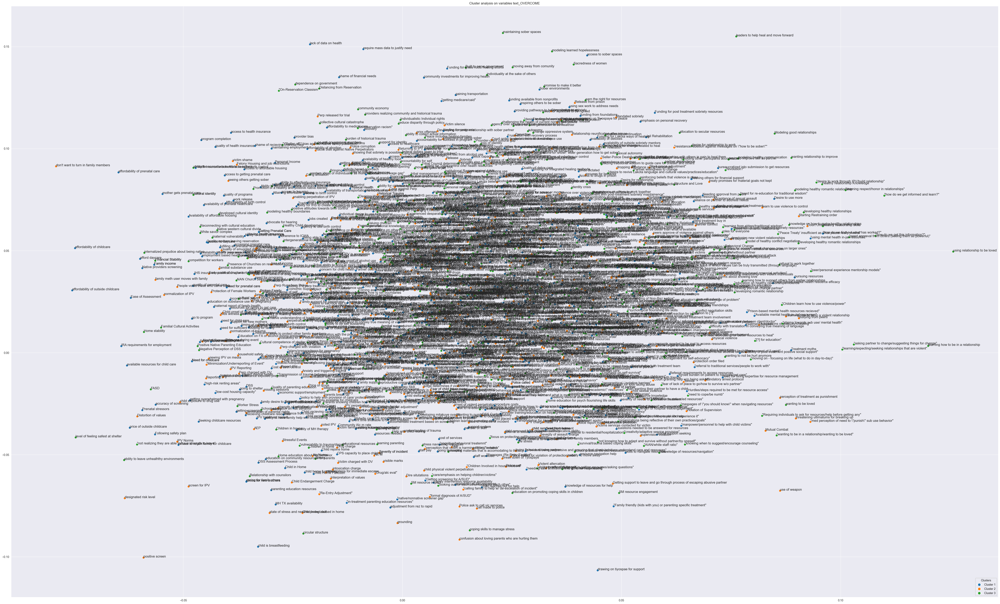

In [111]:
annotations = {float(x): name for x, name in zip(X[:, 0], df_var_cluster['cld variable'])}

fig, ax = plt.subplots(figsize=(50, 30))
ax = cluster_plot(X, group_labels, cluster_labels, annotations = annotations, ax = ax)
plt.title("Cluster analysis on variables text_OVERCOME")
plt.tight_layout()
plt.savefig('Output/SYNCH/Cluster/Cluster analysis vartext -SYNCH.png')
plt.show()


In [112]:
# download as csv 
df_var_cluster.to_csv('Output/SYNCH/Cluster/Cluster_SYNCH.csv', index=False)

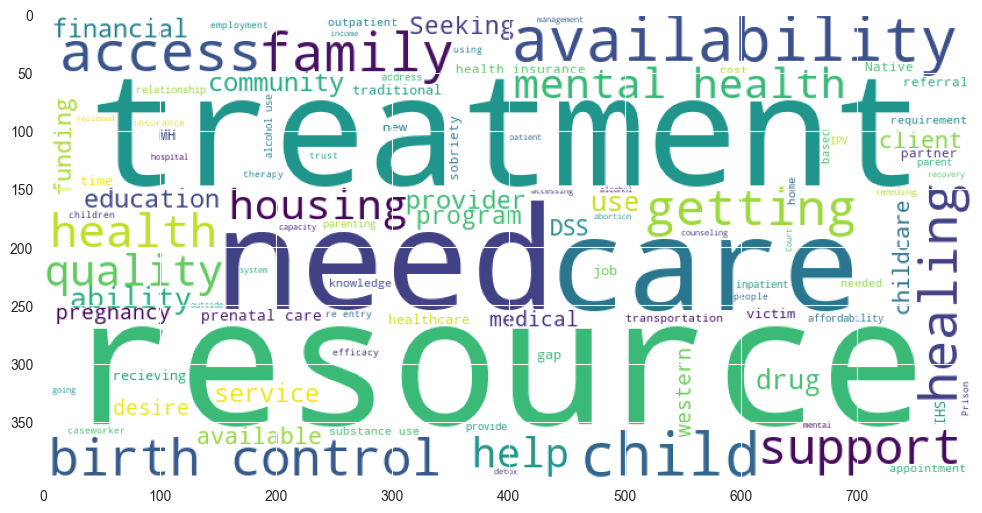

In [113]:

# print these words in a word cloud 
from wordcloud import WordCloud
import matplotlib.pyplot as plt
# Get the variable names in cluster 0
cluster_0_vars = df_var_cluster.loc[df_var_cluster['cluster'] == 0, 'cld variable']
# Create a WordCloud for the variables in cluster 0
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(' '.join(cluster_0_vars))
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud)


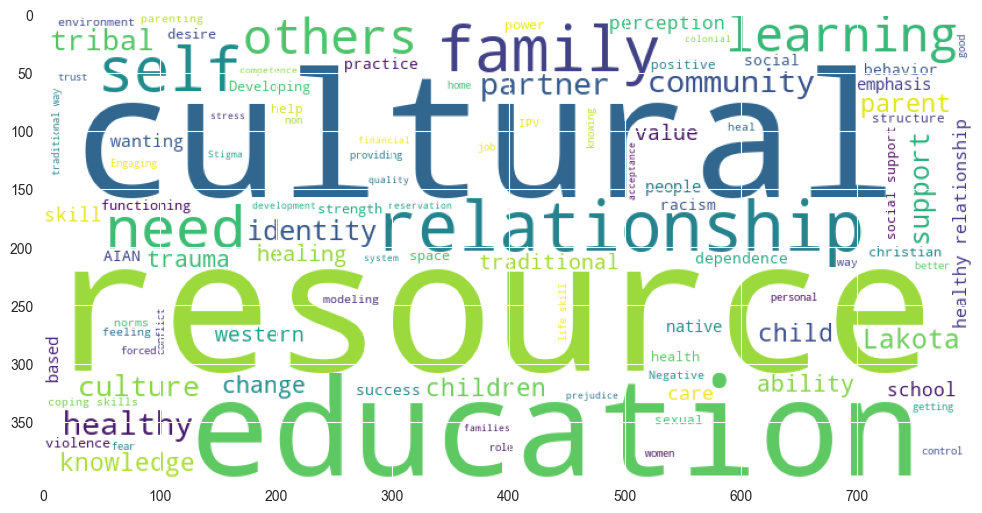

In [114]:

cluster_0_vars = df_var_cluster.loc[df_var_cluster['cluster'] == 2, 'cld variable']
# Create a WordCloud for the variables in cluster 0
wordcloud = WordCloud(width=800, height=400, background_color='white',  max_words=100).generate(' '.join(cluster_0_vars))
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud)

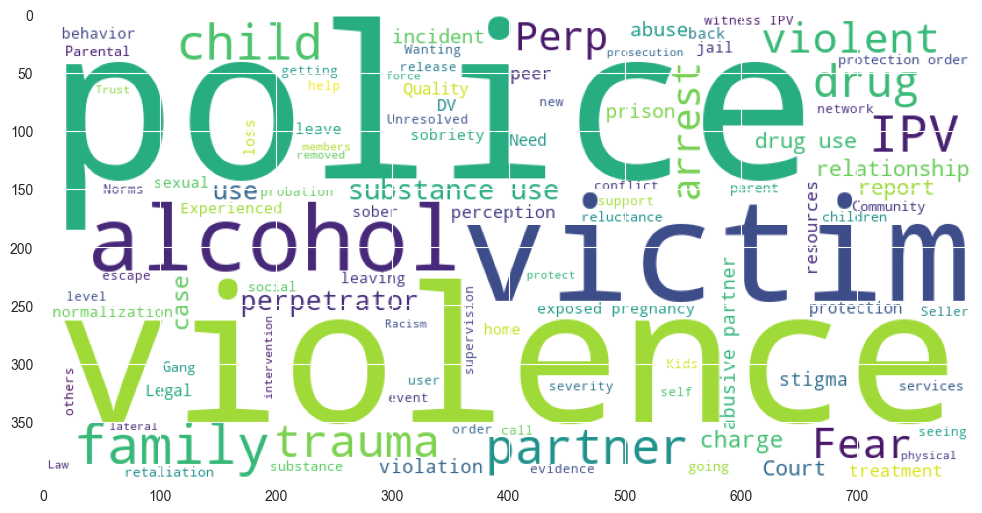

In [115]:
cluster_0_vars = df_var_cluster.loc[df_var_cluster['cluster'] == 1, 'cld variable']
# Create a WordCloud for the variables in cluster 0
wordcloud = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(' '.join(cluster_0_vars))
plt.figure(figsize=(12, 8))
plt.imshow(wordcloud)

# IGNORE

# Cosine Similarity 

Using Cosine Simil arity to calculate the similarity between the embeddings of the variables in the datasets. 
The result shows that most datasets have some similarity, indicating that there may be some overlap in the variables used across the datasets.



In [37]:
similarity_matrix = pd.DataFrame(index=df_cld.index, columns=df_cld.index)

for i in range(0, len(my_data)): 
    for j in range(0, len(my_data)):
        if i != j:
            embedding1 = df_cld['embeddings'].iloc[i].unsqueeze(0)
            embedding2 = df_cld['embeddings'].iloc[j].unsqueeze(0)
            
            similarity_score = torch.nn.functional.cosine_similarity(embedding1, embedding2)
            # store the score in the similarity matrix
            similarity_matrix.loc[i, j] = similarity_score.item()

similarity_matrix.columns = df_cld['dataset']
similarity_matrix.index = df_cld['dataset']
similarity_matrix

NameError: name 'df_cld' is not defined

In [38]:
similarity_matrix = similarity_matrix.astype(float)
sns.heatmap(similarity_matrix, annot=True)

NameError: name 'similarity_matrix' is not defined

In [39]:
# df_cld['cld_vars'] = df_cld['vars'].apply(listToString)

In [40]:
# create_heatmap(cosine_similarity(arr))

# Using pre-trained sentence transformer to compute text similarity

Sentence transformer models captures semantic information in text and can be used to compute text similarity. Here, we use the 'universal-sentence-encoder' model to compute the similarity between the variables in the datasets.

In [ ]:
from absl import logging
import tensorflow as tf
import tensorflow_hub as hub

module_url = "https://tfhub.dev/google/universal-sentence-encoder/4"
model = hub.load(module_url)
print ("module %s loaded" % module_url)
def embed(input):
  return model(input)


2024-05-16 19:49:58.912132: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
message_embeddings_ = embed(string_list)

corr = np.inner(message_embeddings_, message_embeddings_)

In [ ]:
create_heatmap(corr)

In [ ]:
df_cluster

In [ ]:
fig, ax = plt.subplots()
ax.scatter(X[:,0], X[:,1])
colors = ['r', 'g']
plt.title("Cluster of OverCome")
for i, txt in enumerate(df_cluster['label']):
    ax.annotate(txt, (X[i,0], X[i,1]))
    # get different color based on cluster label in df_cluster
    color = colors[df_cluster['cluster'][i]]
    
    ax.scatter(X[i,0], X[i,1], c=color)

In [ ]:

# from sklearn.feature_extraction.text import CountVectorizer
# vectorizer = CountVectorizer()
# vectorizer.fit(list(df_cld['cld_vars']))
# print(vectorizer.vocabulary_)